In [95]:
import sys
import pandas as pd
sys.path.append("..")
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from src.data import load_prices

In [3]:
DB_PATH = "../../financial-data-pipeline/data/market.db"

In [4]:
load_prices(DB_PATH, "SPY").head()

,adj_close
date,
2014-01-02,147.831345
2014-01-03,147.807159
2014-01-06,147.378738
2014-01-07,148.283936
2014-01-08,148.316269


In [5]:
load_prices(DB_PATH, "QQQ").head()

,adj_close
date,
2014-01-02,78.874672
2014-01-03,78.305305
2014-01-06,78.016083
2014-01-07,78.739098
2014-01-08,78.910820


In [7]:
from src.signals import ma_signal

In [8]:
spy = load_prices(DB_PATH, "SPY")

In [14]:
spy_signal = ma_signal(spy["adj_close"])

In [15]:
spy_signal.value_counts()

adj_close
1    2307
0     895
Name: count, dtype: int64

In [16]:
type(spy_signal)

pandas.Series

In [17]:
from src.engine import run_backtest

In [ ]:
run_backtest(spy["adj_close"], spy_signal.iloc[1:])

ValueError: prices and signal must have the same dates

In [19]:
bt = run_backtest(spy["adj_close"], spy_signal)

In [20]:
bt.loc["2014-04-08":"2014-04-11"]

,daily_return,position,strat_ret
date,,,
2014-04-08,0.004123,1.0,0.004123
2014-04-09,0.010751,1.0,0.010751
2014-04-10,-0.021006,1.0,-0.021006
2014-04-11,-0.009009,0.0,-0.000000


In [21]:
bt.head()

,daily_return,position,strat_ret
date,,,
2014-01-02,NaN,NaN,NaN
2014-01-03,-0.000164,0.0,-0.0
2014-01-06,-0.002899,0.0,-0.0
2014-01-07,0.006142,0.0,0.0
2014-01-08,0.000218,0.0,0.0


In [ ]:
bh_equity = (1 + bt["daily_return"].fillna(0)).cumprod()
strat_equity = (1 + bt["strat_ret"].fillna(0)).cumprod()  

In [28]:
print(bh_equity.iloc[-1], strat_equity.iloc[-1])

5.217770139679148 2.2493385991812542


In [30]:
strat_equity.head(10)

date
2014-01-02    1.0
2014-01-03    1.0
2014-01-06    1.0
2014-01-07    1.0
2014-01-08    1.0
2014-01-09    1.0
2014-01-10    1.0
2014-01-13    1.0
2014-01-14    1.0
2014-01-15    1.0
Name: strat_ret, dtype: float64

In [31]:
bt.head(10)

,daily_return,position,strat_ret
date,,,
2014-01-02,NaN,NaN,NaN
2014-01-03,-0.000164,0.0,-0.0
2014-01-06,-0.002899,0.0,-0.0
2014-01-07,0.006142,0.0,0.0
2014-01-08,0.000218,0.0,0.0
2014-01-09,0.000654,0.0,0.0
2014-01-10,0.002723,0.0,0.0
2014-01-13,-0.013305,0.0,-0.0
2014-01-14,0.010898,0.0,0.0


In [33]:
import matplotlib.pyplot as plt

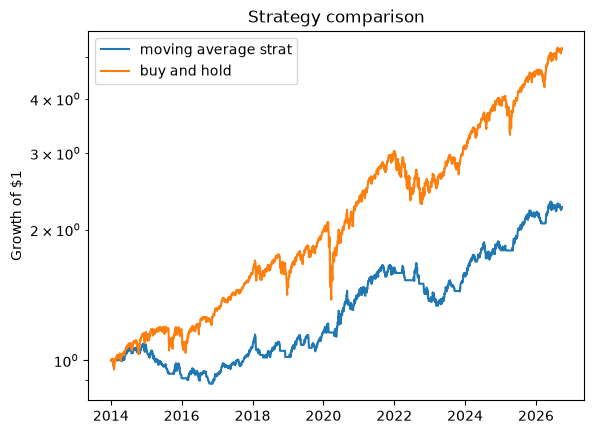

In [ ]:
plt.plot(bt.index, strat_equity, label = "moving average strat")
plt.plot(bt.index, bh_equity, label = "buy and hold")
plt.legend()
plt.title("SPY: MA50 rule vs buy-and-hold (before costs)")
plt.ylabel("Growth of $1")
plt.yscale("log")
plt.show()

In [71]:
bt = run_backtest(spy["adj_close"], spy_signal)

In [72]:
bt.head()

,daily_return,position,strat_ret,turnover,net_ret
date,,,,,
2014-01-02,NaN,0.0,NaN,0.0,NaN
2014-01-03,-0.000164,0.0,-0.0,0.0,-0.0
2014-01-06,-0.002899,0.0,-0.0,0.0,-0.0
2014-01-07,0.006142,0.0,0.0,0.0,0.0
2014-01-08,0.000218,0.0,0.0,0.0,0.0


In [39]:
bh_equity = (1 + bt["daily_return"].fillna(0)).cumprod()
strat_equity = (1 + bt["strat_ret"].fillna(0)).cumprod()  
print(bh_equity.iloc[-1], strat_equity.iloc[-1])

5.217770139679148 2.2493385991812542


In [74]:
bt_10 = run_backtest(spy["adj_close"], spy_signal, cost_bps=10)
bh_equity_10 = (1 + bt_10["daily_return"].fillna(0)).cumprod()
strat_equity_10 = (1 + bt_10["net_ret"].fillna(0)).cumprod()  
print(bh_equity_10.iloc[-1], strat_equity_10.iloc[-1])

5.217770139679148 1.7890097838625305


In [75]:
bt_30 = run_backtest(spy["adj_close"], spy_signal, cost_bps=30)
strat_equity_30 = (1 + bt_30["net_ret"].fillna(0)).cumprod()  
print(strat_equity_30.iloc[-1])

1.1309142386985358


In [43]:
bt_10["turnover"].sum()

np.float64(229.0)

In [48]:
from src.metrics import cagr
cagr(bt["daily_return"]), cagr(bt_10["net_ret"])

(np.float64(0.13889657768739672), np.float64(0.046856217269904965))

In [50]:
from src.metrics import ann_vol
ann_vol(bt["daily_return"]), ann_vol(bt_10["net_ret"])


(np.float64(0.17125907238370874), np.float64(0.10287454569728885))

In [51]:
from src.metrics import sharpe
sharpe(bt["daily_return"]), sharpe(bt_10["net_ret"])


(np.float64(0.8454596650234235), np.float64(0.4967675739842907))

In [55]:
from src.metrics import max_drawdown
max_drawdown(bt["daily_return"]), max_drawdown(bt_10["net_ret"])


(np.float64(-0.3371727855161352), np.float64(-0.2426665118918144))

In [56]:
from src.metrics import drawdown_series
drawdown_series(bt["daily_return"]).idxmin(), drawdown_series(bt_10["net_ret"]).idxmin()

(Timestamp('2020-03-23 00:00:00'), Timestamp('2016-11-11 00:00:00'))

In [ ]:
from src.signals import momentum_signal
mom_signal = momentum_signal(spy["adj_close"])
bt_mom = run_backtest(spy["adj_close"], mom_signal, cost_bps=10)

np.float64(55.0)

In [65]:
bt_mom.tail()

,daily_return,position,strat_ret,turnover,net_ret
date,,,,,
2026-09-21,0.015505,1.0,0.015505,0.0,0.015505
2026-09-22,-0.000155,1.0,-0.000155,0.0,-0.000155
2026-09-23,-0.007202,1.0,-0.007202,0.0,-0.007202
2026-09-24,-0.000821,1.0,-0.000821,0.0,-0.000821
2026-09-25,0.005435,1.0,0.005435,0.0,0.005435


In [64]:
mom_signal.tail()

date
2026-09-21    1
2026-09-22    1
2026-09-23    1
2026-09-24    1
2026-09-25    1
Name: adj_close, dtype: int64

In [66]:
print(bt_mom["turnover"].sum())

55.0


In [ ]:
runs = [("Buy and hold", bt_mom["daily_return"]),
         ("MA50, 0 bps", bt["net_ret"]),
         ("MA50, 10 bps", bt_10["net_ret"]),
         ("MA50, 30 bps", bt_30["net_ret"]),
         ("Momentum, 10 bps", bt_mom["net_ret"]),
         ]
for name, r in runs:
    print(f"{name}:\n CAGR = {cagr(r):.1%}, annualized volatility = {ann_vol(r):.1%}, Sharpe ratio = {sharpe(r):.3f}, Maximum drawdown = {max_drawdown(r):.1%}")

Buy and hold:
 cagr = 13.9%, annualized volatility = 17.1%, Sharpe ratio = 0.845, Maximum drawdown = -33.7%
MA50, 0 bps:
 cagr = 6.6%, annualized volatility = 10.3%, Sharpe ratio = 0.672, Maximum drawdown = -20.3%
MA50, 10 bps:
 cagr = 4.7%, annualized volatility = 10.3%, Sharpe ratio = 0.497, Maximum drawdown = -24.3%
MA50, 30 bps:
 cagr = 1.0%, annualized volatility = 10.3%, Sharpe ratio = 0.146, Maximum drawdown = -34.1%
Momentum, 10 bps:
 cagr = 6.8%, annualized volatility = 13.4%, Sharpe ratio = 0.559, Maximum drawdown = -31.6%


In [87]:
from src.metrics import summary
for name, r in runs:
    print(f"{name}: \n{summary(r)}")

Buy and hold: 
CAGR            0.138897
Volatility      0.171259
Sharpe          0.845460
Max Drawdown   -0.337173
dtype: float64
MA50, 0 bps: 
CAGR            0.065898
Volatility      0.102860
Sharpe          0.672106
Max Drawdown   -0.202598
dtype: float64
MA50, 10 bps: 
CAGR            0.046856
Volatility      0.102875
Sharpe          0.496768
Max Drawdown   -0.242667
dtype: float64
MA50, 30 bps: 
CAGR            0.009732
Volatility      0.103390
Sharpe          0.145550
Max Drawdown   -0.341487
dtype: float64
Momentum, 10 bps: 
CAGR            0.068165
Volatility      0.134073
Sharpe          0.559493
Max Drawdown   -0.315813
dtype: float64


In [90]:
results = {}
for name, r in runs:
    results[name] = summary(r)
print(results)

{'Buy and hold': CAGR            0.138897
Volatility      0.171259
Sharpe          0.845460
Max Drawdown   -0.337173
dtype: float64, 'MA50, 0 bps': CAGR            0.065898
Volatility      0.102860
Sharpe          0.672106
Max Drawdown   -0.202598
dtype: float64, 'MA50, 10 bps': CAGR            0.046856
Volatility      0.102875
Sharpe          0.496768
Max Drawdown   -0.242667
dtype: float64, 'MA50, 30 bps': CAGR            0.009732
Volatility      0.103390
Sharpe          0.145550
Max Drawdown   -0.341487
dtype: float64, 'Momentum, 10 bps': CAGR            0.068165
Volatility      0.134073
Sharpe          0.559493
Max Drawdown   -0.315813
dtype: float64}


In [ ]:
results_table = pd.DataFrame(results).T.round(3)
results_table

,CAGR,Volatility,Sharpe,Max Drawdown
Buy and hold,0.139,0.171,0.845,-0.337
"MA50, 0 bps",0.066,0.103,0.672,-0.203
"MA50, 10 bps",0.047,0.103,0.497,-0.243
"MA50, 30 bps",0.010,0.103,0.146,-0.341
"Momentum, 10 bps",0.068,0.134,0.559,-0.316


In [ ]:
grid = {}
windows = [20, 50, 100, 150, 200, 252]
start_date = spy.index[252]
for w in windows:
    sig  = ma_signal(spy['adj_close'], w)
    backtest = run_backtest(spy['adj_close'], sig, cost_bps=10)
    grid[w] = summary(backtest['net_ret'].loc[start_date:])
table = pd.DataFrame(grid).T.round(3)

In [97]:
table

,CAGR,Volatility,Sharpe,Max Drawdown
20,0.038,0.103,0.414,-0.259
50,0.046,0.105,0.481,-0.227
100,0.083,0.112,0.768,-0.196
150,0.085,0.117,0.756,-0.225
200,0.098,0.118,0.849,-0.216
252,0.086,0.122,0.734,-0.245


In [99]:
bh_stats = summary(backtest["daily_return"].loc[start_date:])
bh_stats

CAGR            0.138274
Volatility      0.175381
Sharpe          0.826554
Max Drawdown   -0.337173
dtype: float64

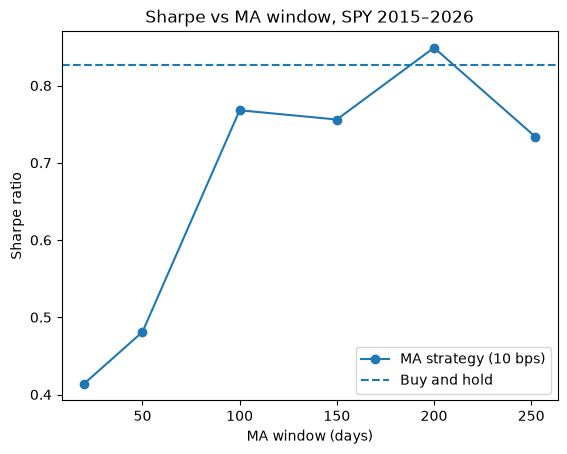

In [100]:
plt.plot(table.index, table["Sharpe"], marker="o", label="MA strategy (10 bps)")
plt.axhline(y=bh_stats["Sharpe"], linestyle="--", label="Buy and hold")
plt.xlabel("MA window (days)")
plt.ylabel("Sharpe ratio")
plt.title("Sharpe vs MA window, SPY 2015–2026")
plt.legend()
plt.show()

In [101]:
is_end = "2020-12-31"
oos_start = "2021-01-01"
split = {}

for w in windows:
    sig = ma_signal(spy['adj_close'], w)
    backtest = run_backtest(spy['adj_close'], sig, cost_bps=10)
    is_r  = backtest['net_ret'].loc[start_date:is_end]
    oos_r = backtest['net_ret'].loc[oos_start:]
    split[w] = {"IS Sharpe": sharpe(is_r), "OOS Sharpe": sharpe(oos_r)}
table_split = pd.DataFrame(split).T.round(3)

table_split


,IS Sharpe,OOS Sharpe
20,0.489,0.340
50,0.325,0.631
100,0.530,1.005
150,0.419,1.115
200,0.704,1.007
252,0.626,0.849


In [102]:
table_split["IS Sharpe"].idxmax()

np.int64(200)

In [105]:
sharpe(backtest["daily_return"].loc[start_date:is_end])

np.float64(0.7429843565775137)

In [106]:
sharpe(backtest["daily_return"].loc[oos_start:])

np.float64(0.9248187701819025)